In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pickle
import json
import warnings

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 11

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("bank-full.csv", sep=";")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [6]:
df.info()

print(df.shape)

display(df.isnull().sum().sort_values(ascending=False))

print(df.duplicated().sum())

display(df["y"].value_counts())

display(df["y"].value_counts(normalize=True) * 100)

display(df.describe())

display(df.describe(include=["object"]))

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB
(45211, 17)


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

0


y
no     39922
yes     5289
Name: count, dtype: int64

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


In [9]:
print(df["y"].unique())

assert set(df["y"].unique()) == {"yes", "no"}

display(df.dtypes)

categorical_features = df.select_dtypes(include=["object"]).columns.tolist()

categorical_features.remove("y")

print(categorical_features)

numerical_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print(numerical_features)


<StringArray>
['no', 'yes']
Length: 2, dtype: str


age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


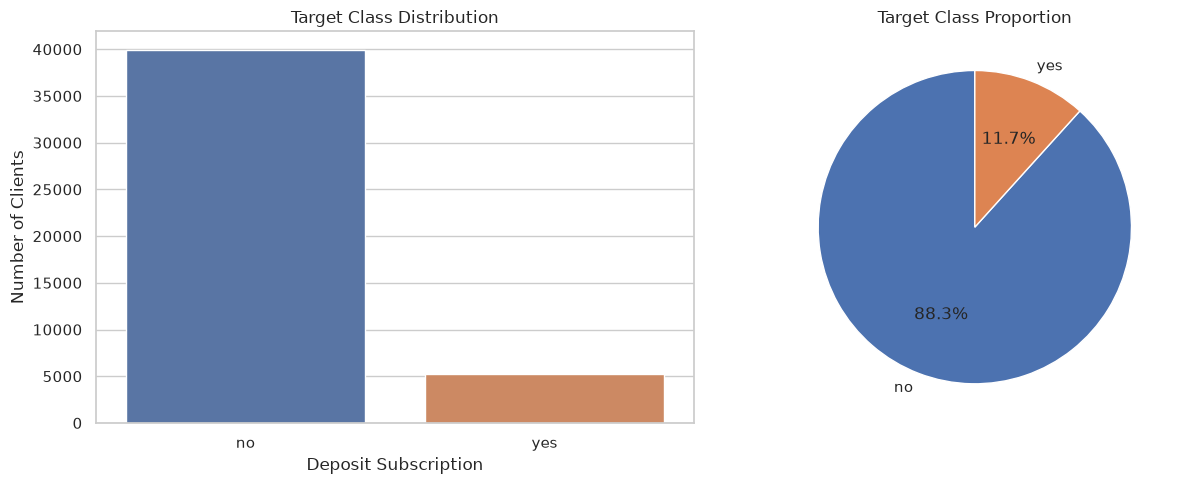

In [10]:
target_counts = df["y"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=df,
    x="y",
    hue="y",
    order=["no", "yes"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Target Class Distribution")
axes[0].set_xlabel("Deposit Subscription")
axes[0].set_ylabel("Number of Clients")

axes[1].pie(
    target_counts,
    labels=target_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

axes[1].set_title("Target Class Proportion")

plt.tight_layout()
plt.show()

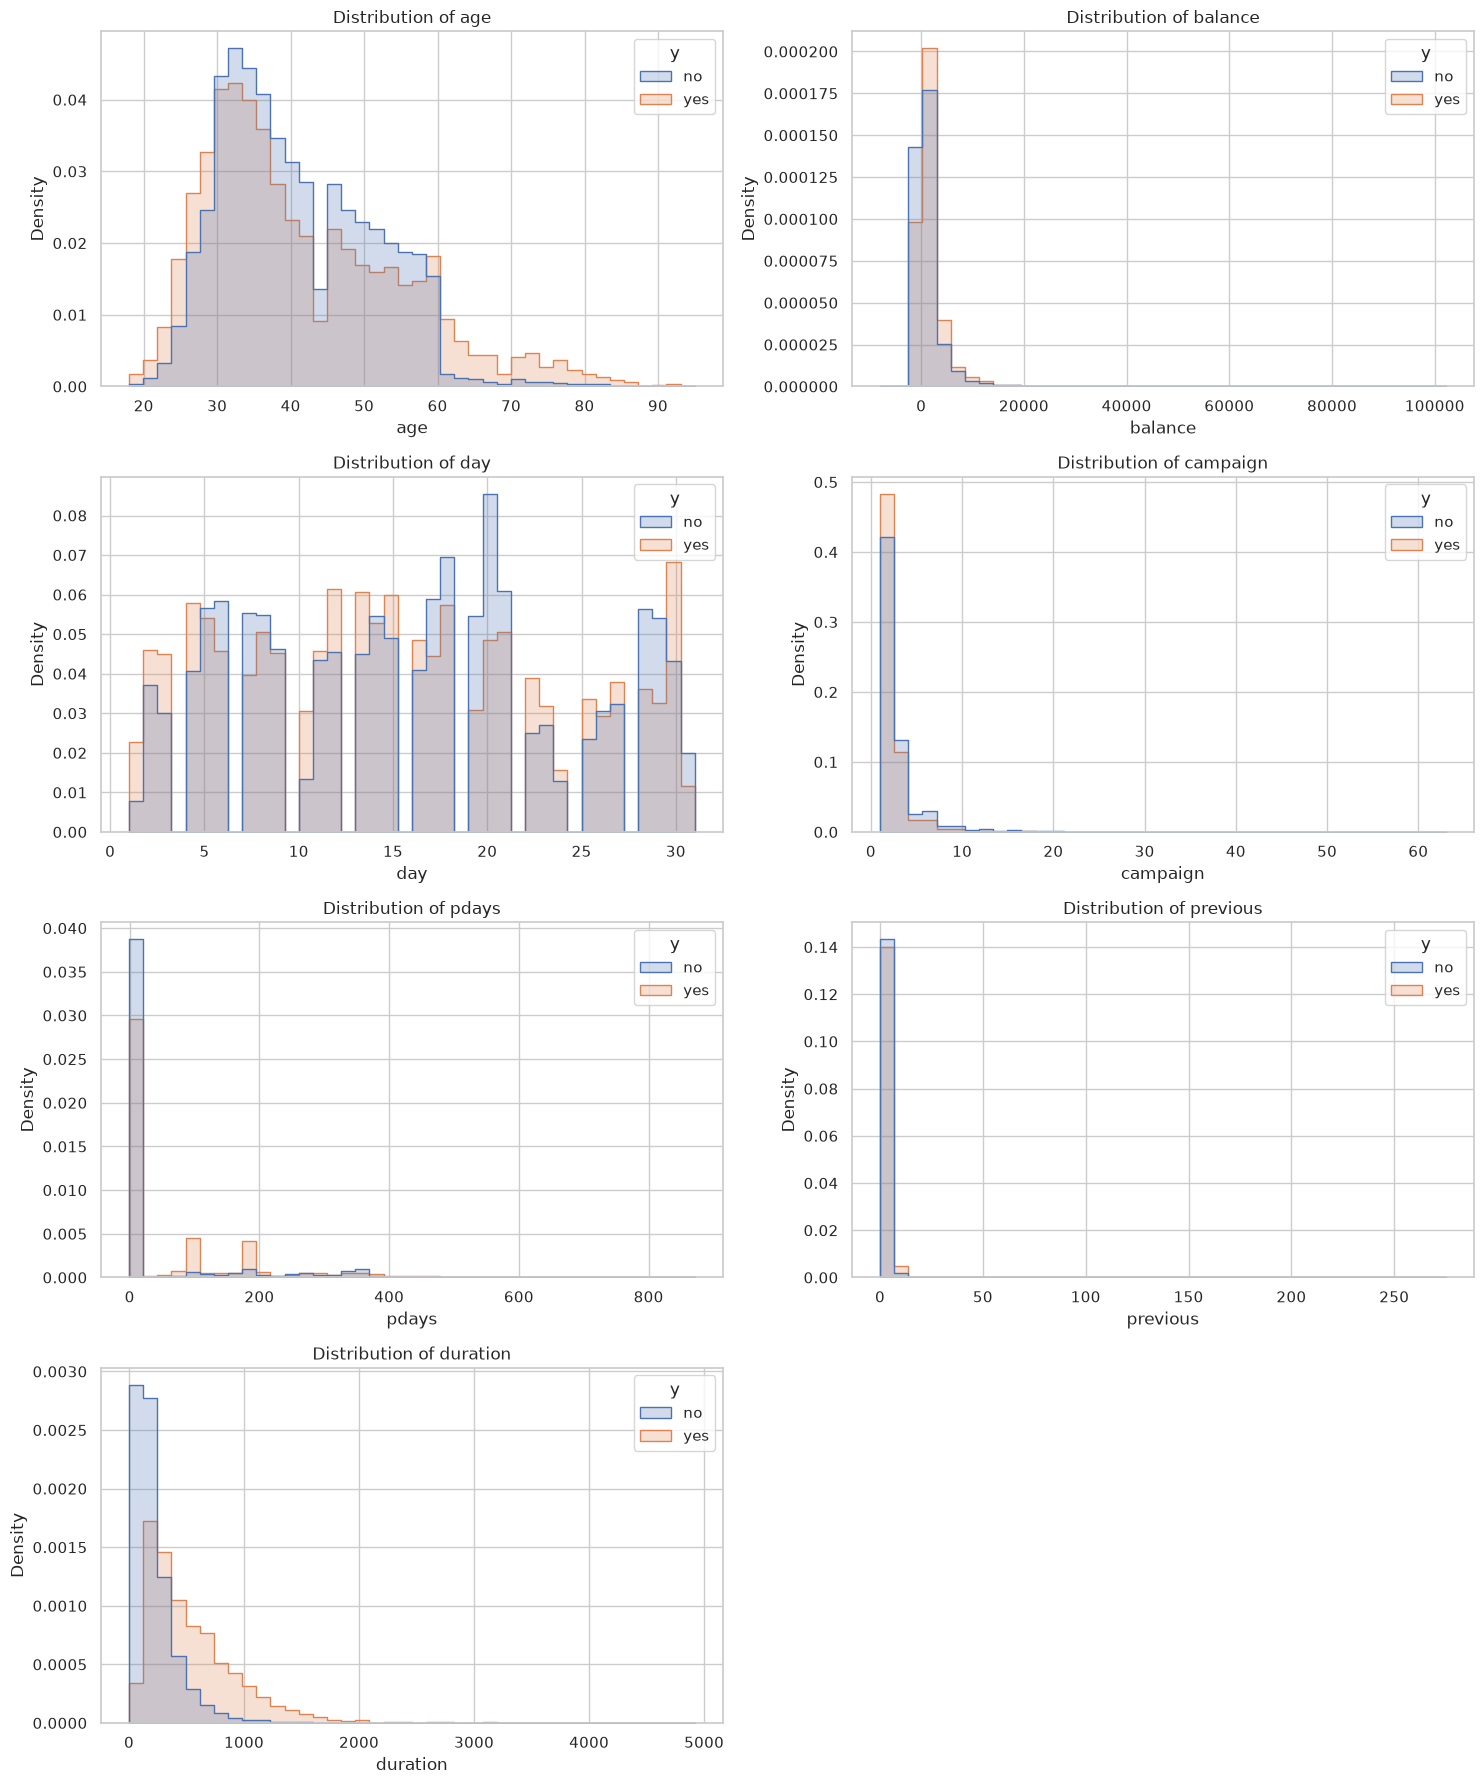

In [11]:
numerical_features = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous",
    "duration"
]

fig, axes = plt.subplots(
    4, 2,
    figsize=(15, 18)
)

axes = axes.flatten()

for i, feature in enumerate(numerical_features):

    sns.histplot(
        data=df,
        x=feature,
        hue="y",
        bins=40,
        element="step",
        stat="density",
        common_norm=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Distribution of {feature}"
    )

axes[-1].axis("off")

plt.tight_layout()
plt.show()

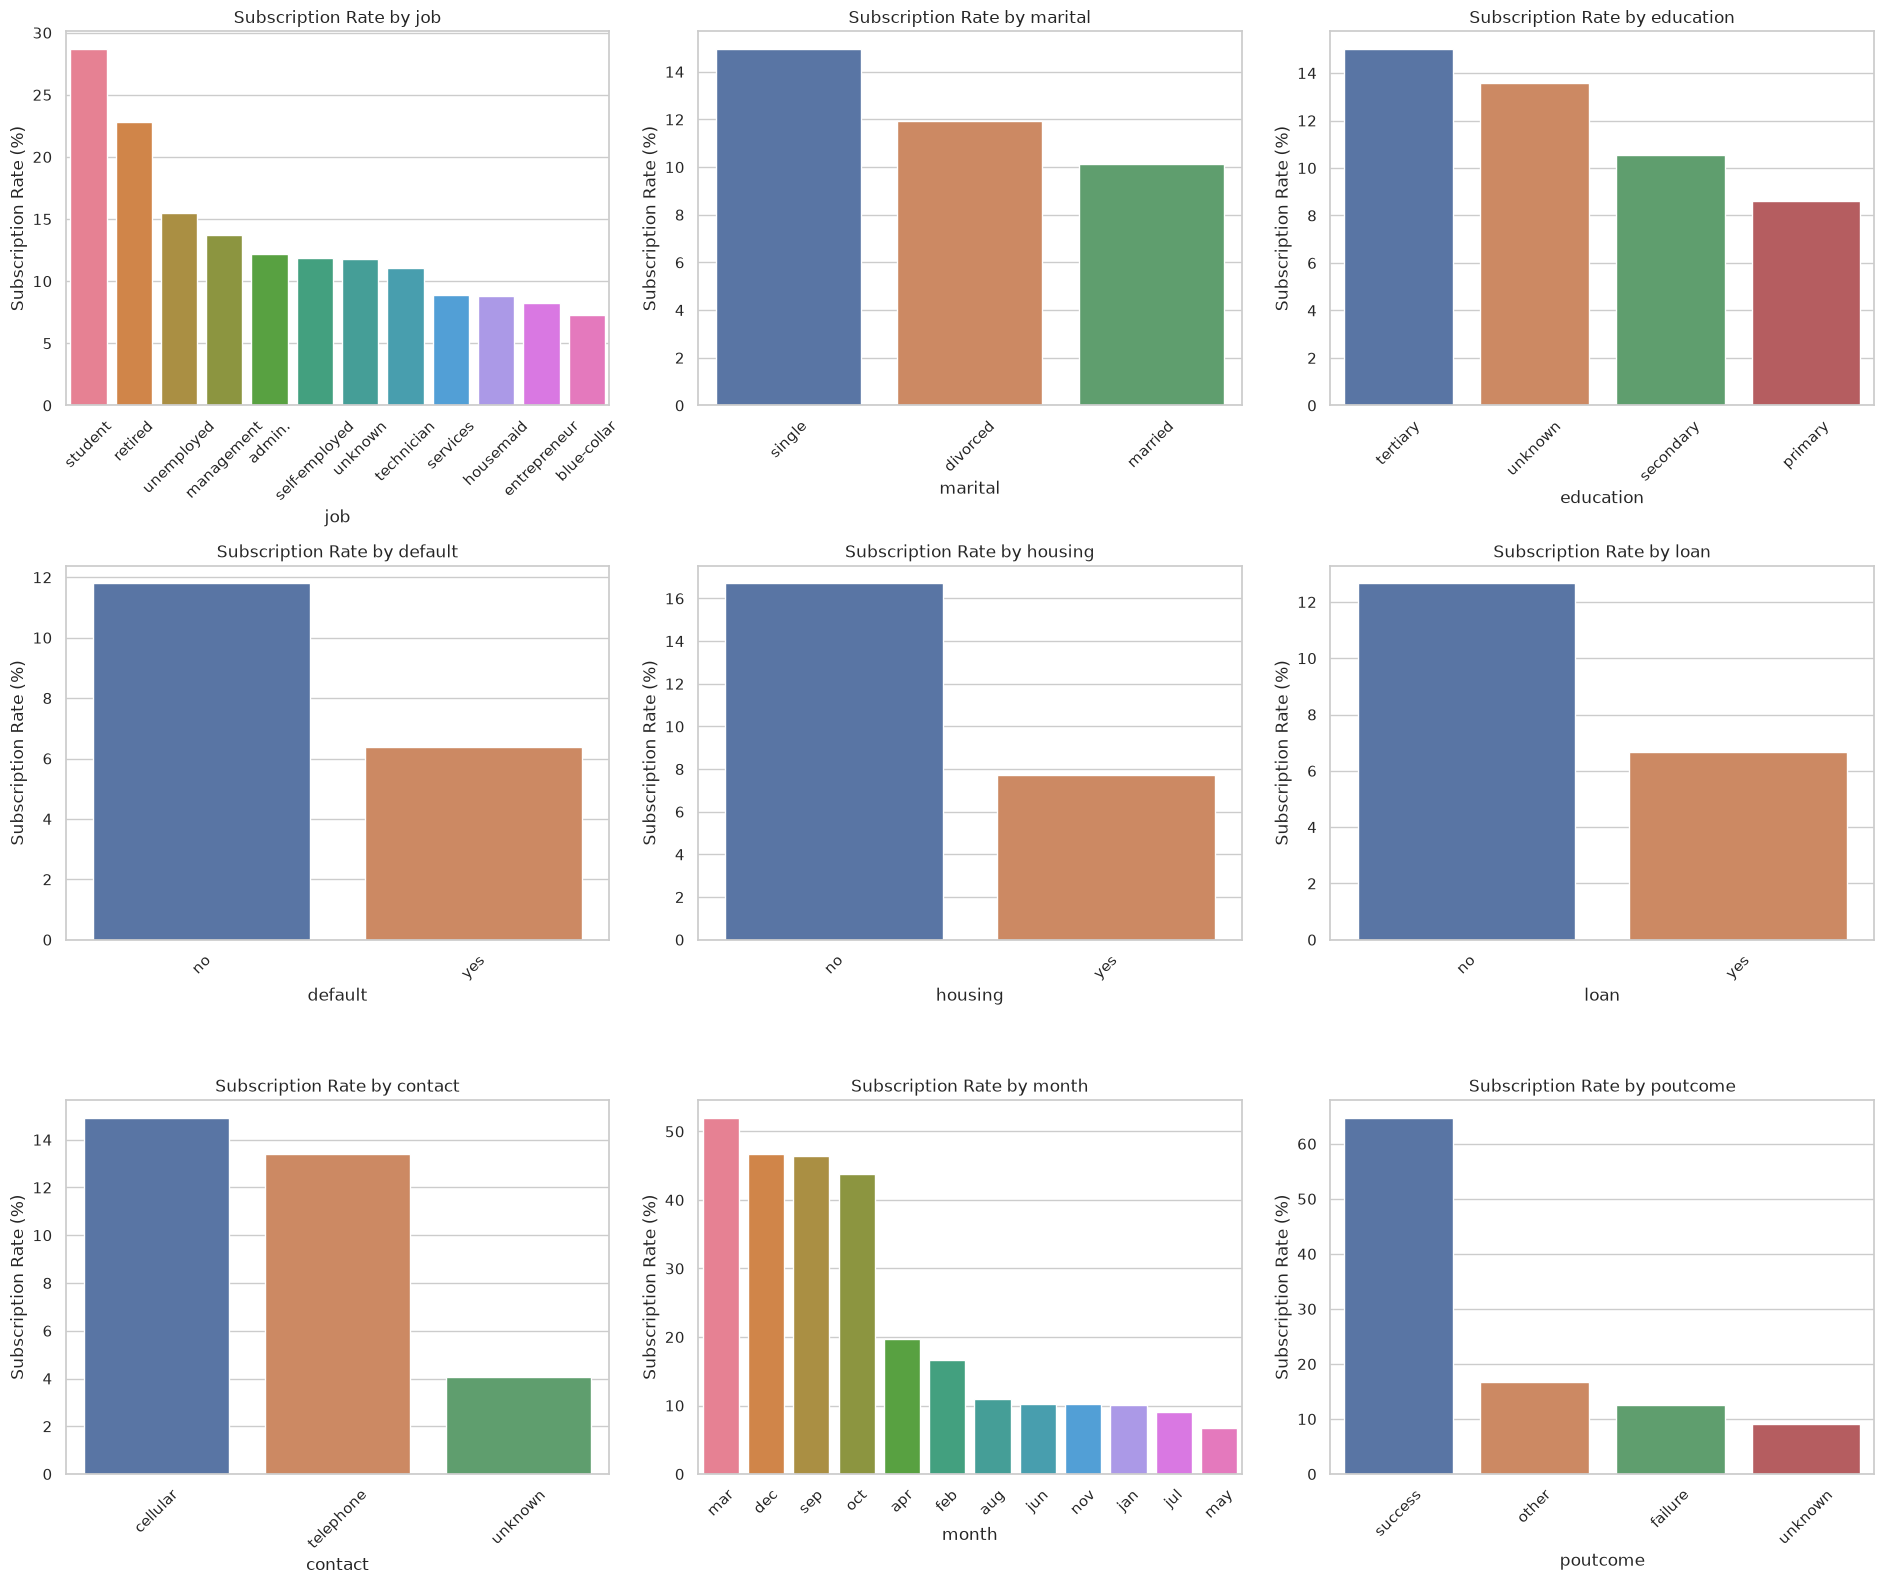

In [12]:
categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome"
]

fig, axes = plt.subplots(
    3, 3,
    figsize=(19, 16)
)

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    conversion = (
        df.groupby(feature, observed=False)["y"]
        .apply(lambda x: (x == "yes").mean() * 100)
        .sort_values(ascending=False)
        .reset_index(name="subscription_rate")
    )

    sns.barplot(
        data=conversion,
        x=feature,
        y="subscription_rate",
        hue=feature,
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Subscription Rate by {feature}"
    )

    axes[i].set_ylabel("Subscription Rate (%)")
    axes[i].set_xlabel(feature)

    axes[i].tick_params(
        axis="x",
        rotation=45
    )

plt.tight_layout()
plt.show()

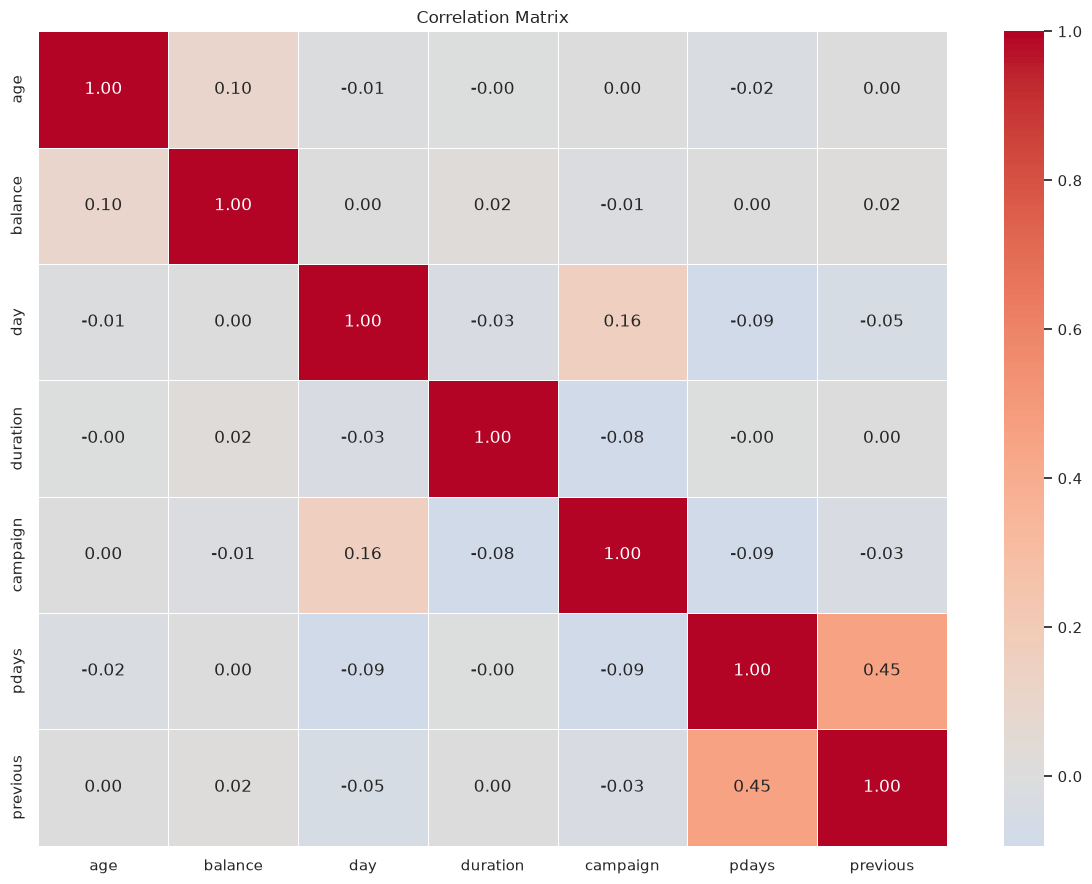

In [14]:
correlation = df.select_dtypes(
    include=["int64", "float64"]
).corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [15]:
TARGET = "y"

EXCLUDED_FEATURES = [
    "duration"
]

FEATURES = [
    col for col in df.columns
    if col not in [TARGET] + EXCLUDED_FEATURES
]

print("Selected features:")
print(FEATURES)

print("\nExcluded features:")
print(EXCLUDED_FEATURES)

print(f"\nNumber of selected features: {len(FEATURES)}")

X = df[FEATURES]
y = (df[TARGET] == "yes").astype(int)

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

Selected features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Excluded features:
['duration']

Number of selected features: 15

Feature matrix shape: (45211, 15)
Target shape: (45211,)


In [16]:
X_full_train, X_test, y_full_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_full_train,
    y_full_train,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_full_train
)

X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTarget distribution:")

for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:

    print(
        f"{name}: "
        f"positive={target.mean():.4f}, "
        f"negative={1 - target.mean():.4f}"
    )

Train: (27126, 15)
Validation: (9042, 15)
Test: (9043, 15)

Target distribution:
Train: positive=0.1170, negative=0.8830
Validation: positive=0.1170, negative=0.8830
Test: positive=0.1170, negative=0.8830


In [17]:
train_dicts = X_train.to_dict(orient="records")
val_dicts = X_val.to_dict(orient="records")
test_dicts = X_test.to_dict(orient="records")

dv = DictVectorizer(sparse=False)

X_train_encoded = dv.fit_transform(train_dicts)
X_val_encoded = dv.transform(val_dicts)
X_test_encoded = dv.transform(test_dicts)

print("Encoded datasets:")

print("Train:", X_train_encoded.shape)
print("Validation:", X_val_encoded.shape)
print("Test:", X_test_encoded.shape)

print("\nNumber of encoded features:")
print(len(dv.get_feature_names_out()))

Encoded datasets:
Train: (27126, 50)
Validation: (9042, 50)
Test: (9043, 50)

Number of encoded features:
50


Decision tree

In [18]:
import xgboost as xgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

def evaluate_model(y_true, y_prob, threshold=0.5):
    
    y_pred = (y_prob >= threshold).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        )
    }


print("Evaluation function created successfully")

Evaluation function created successfully


In [19]:
dt_scores = []

depth_values = [3, 5, 7, 10, 15, 20, None]
leaf_values = [1, 5, 10, 20, 50, 100]

for depth in depth_values:
    for leaf in leaf_values:

        dt_model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=RANDOM_STATE
        )

        dt_model.fit(
            X_train_encoded,
            y_train
        )

        y_val_prob = dt_model.predict_proba(
            X_val_encoded
        )[:, 1]

        metrics = evaluate_model(
            y_val,
            y_val_prob
        )

        dt_scores.append({
            "max_depth": depth,
            "min_samples_leaf": leaf,
            **metrics
        })

dt_results = pd.DataFrame(dt_scores)

dt_results = dt_results.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(dt_results.head(10))

best_dt_params = dt_results.iloc[0]

print("\nBest Decision Tree parameters:")
print(best_dt_params)

,max_depth,min_samples_leaf,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,15.0,50,0.768319,0.411732,0.892833,0.636086,0.196597,0.300361
1,20.0,100,0.766488,0.408247,0.892612,0.618529,0.214556,0.318596
2,NaN,100,0.765375,0.407535,0.892612,0.618529,0.214556,0.318596
3,15.0,100,0.763950,0.403543,0.892612,0.618529,0.214556,0.318596
4,15.0,20,0.762289,0.403364,0.892723,0.594421,0.261815,0.363517
5,20.0,20,0.759143,0.397946,0.892170,0.587368,0.263705,0.363992
6,NaN,50,0.759135,0.412351,0.892833,0.636086,0.196597,0.300361
7,20.0,50,0.756389,0.412035,0.892833,0.636086,0.196597,0.300361
8,10.0,100,0.751533,0.375984,0.893055,0.634218,0.203214,0.307802
9,10.0,50,0.750125,0.375190,0.892723,0.640127,0.189981,0.293003



Best Decision Tree parameters:
max_depth           15.000000
min_samples_leaf    50.000000
ROC-AUC              0.768319
PR-AUC               0.411732
Accuracy             0.892833
Precision            0.636086
Recall               0.196597
F1                   0.300361
Name: 0, dtype: float64


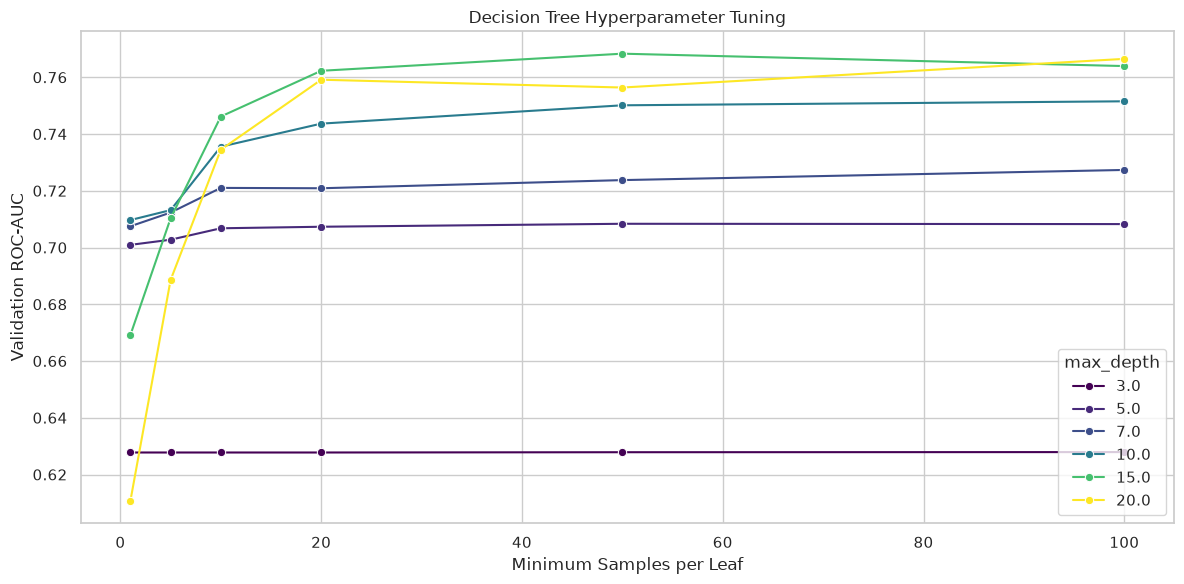

In [20]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=dt_results,
    x="min_samples_leaf",
    y="ROC-AUC",
    hue="max_depth",
    marker="o",
    palette="viridis"
)

plt.title("Decision Tree Hyperparameter Tuning")
plt.xlabel("Minimum Samples per Leaf")
plt.ylabel("Validation ROC-AUC")

plt.tight_layout()
plt.show()


In [21]:
best_dt = DecisionTreeClassifier(
    max_depth=(
        None if pd.isna(best_dt_params["max_depth"])
        else int(best_dt_params["max_depth"])
    ),
    min_samples_leaf=int(
        best_dt_params["min_samples_leaf"]
    ),
    random_state=RANDOM_STATE
)

best_dt.fit(
    X_train_encoded,
    y_train
)

dt_val_predictions = best_dt.predict_proba(
    X_val_encoded
)[:, 1]

print("Decision Tree validation metrics:")

display(
    pd.DataFrame(
        [evaluate_model(y_val, dt_val_predictions)],
        index=["Decision Tree"]
    )
)

Decision Tree validation metrics:


,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
Decision Tree,0.768319,0.411732,0.892833,0.636086,0.196597,0.300361


Ensembles and random forest

In [22]:
rf_scores = []

rf_estimators = [100, 200]
rf_depths = [10, 20]
rf_leaves = [1, 5, 10]

for n_estimators in rf_estimators:
    for depth in rf_depths:
        for leaf in rf_leaves:

            rf_model = RandomForestClassifier(
                n_estimators=n_estimators,
                max_depth=depth,
                min_samples_leaf=leaf,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )

            rf_model.fit(
                X_train_encoded,
                y_train
            )

            y_val_prob = rf_model.predict_proba(
                X_val_encoded
            )[:, 1]

            metrics = evaluate_model(
                y_val,
                y_val_prob
            )

            rf_scores.append({
                "n_estimators": n_estimators,
                "max_depth": depth,
                "min_samples_leaf": leaf,
                **metrics
            })

rf_results = pd.DataFrame(rf_scores)

rf_results = rf_results.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(rf_results.head(10))

best_rf_params = rf_results.iloc[0]

print("\nBest Random Forest parameters:")
print(best_rf_params)

,n_estimators,max_depth,min_samples_leaf,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,200,20,5,0.803067,0.461222,0.895156,0.689655,0.189036,0.296736
1,200,20,10,0.802059,0.459115,0.895488,0.711610,0.179584,0.286792
2,100,20,5,0.801823,0.460207,0.895377,0.693103,0.189981,0.298220
3,100,10,1,0.801664,0.453476,0.894492,0.700000,0.172023,0.276176
4,200,10,1,0.801342,0.455408,0.894492,0.698473,0.172968,0.277273
5,100,20,1,0.800901,0.457318,0.895930,0.664789,0.223062,0.334041
6,100,20,10,0.800795,0.459704,0.895267,0.706320,0.179584,0.286360
7,200,20,1,0.799910,0.457613,0.896262,0.667598,0.225898,0.337571
8,200,10,5,0.799612,0.456345,0.894271,0.704000,0.166352,0.269113
9,100,10,5,0.798702,0.453040,0.894824,0.721992,0.164461,0.267898



Best Random Forest parameters:
n_estimators        200.000000
max_depth            20.000000
min_samples_leaf      5.000000
ROC-AUC               0.803067
PR-AUC                0.461222
Accuracy              0.895156
Precision             0.689655
Recall                0.189036
F1                    0.296736
Name: 0, dtype: float64


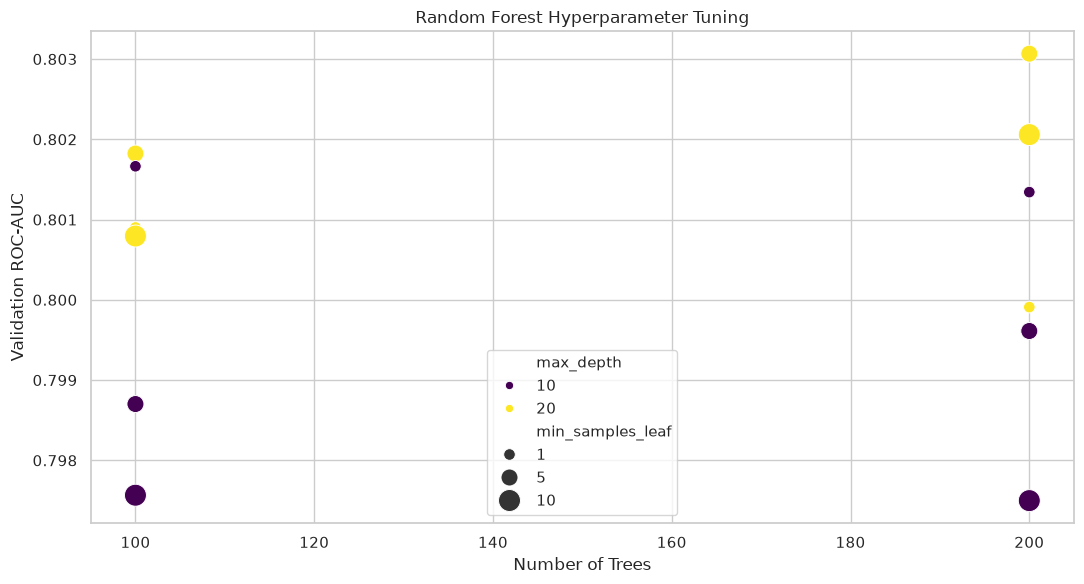

In [23]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=rf_results,
    x="n_estimators",
    y="ROC-AUC",
    hue="max_depth",
    size="min_samples_leaf",
    sizes=(70, 250),
    palette="viridis"
)

plt.title("Random Forest Hyperparameter Tuning")
plt.xlabel("Number of Trees")
plt.ylabel("Validation ROC-AUC")

plt.tight_layout()
plt.show()

In [24]:
best_rf = RandomForestClassifier(
    n_estimators=int(best_rf_params["n_estimators"]),
    max_depth=int(best_rf_params["max_depth"]),
    min_samples_leaf=int(
        best_rf_params["min_samples_leaf"]
    ),
    random_state=RANDOM_STATE,
    n_jobs=-1
)

best_rf.fit(
    X_train_encoded,
    y_train
)

rf_val_predictions = best_rf.predict_proba(
    X_val_encoded
)[:, 1]

print("Random Forest validation metrics:")

display(
    pd.DataFrame(
        [evaluate_model(y_val, rf_val_predictions)],
        index=["Random Forest"]
    )
)

Random Forest validation metrics:


,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
Random Forest,0.803067,0.461222,0.895156,0.689655,0.189036,0.296736


Gradient boosting

In [25]:
features = list(dv.get_feature_names_out())

dtrain = xgb.DMatrix(
    X_train_encoded,
    label=y_train,
    feature_names=features
)

dval = xgb.DMatrix(
    X_val_encoded,
    label=y_val,
    feature_names=features
)

print("XGBoost DMatrix created")
print("Train:", dtrain.num_row())
print("Validation:", dval.num_row())
print("Features:", dtrain.num_col())


XGBoost DMatrix created
Train: 27126
Validation: 9042
Features: 50


In [26]:

xgb_configs = [
    {"eta": 0.03, "max_depth": 4, "min_child_weight": 1},
    {"eta": 0.03, "max_depth": 6, "min_child_weight": 10},
    {"eta": 0.05, "max_depth": 4, "min_child_weight": 10},
    {"eta": 0.05, "max_depth": 6, "min_child_weight": 1},
    {"eta": 0.1, "max_depth": 4, "min_child_weight": 5},
    {"eta": 0.1, "max_depth": 6, "min_child_weight": 10}
]

xgb_scores = []
xgb_models = {}

for i, config in enumerate(xgb_configs):

    params = {
        **config,
        "objective": "binary:logistic",
        "eval_metric": "auc",
        "tree_method": "hist",
        "seed": RANDOM_STATE,
        "nthread": -1,
        "verbosity": 0
    }

    model = xgb.train(
        params=params,
        dtrain=dtrain,
        num_boost_round=300,
        evals=[(dtrain, "train"), (dval, "validation")],
        verbose_eval=False
    )

    y_val_prob = model.predict(dval)

    metrics = evaluate_model(
        y_val,
        y_val_prob
    )

    model_name = f"xgb_model_{i}"

    xgb_models[model_name] = model

    xgb_scores.append({
        "model_name": model_name,
        **config,
        **metrics
    })

xgb_results = pd.DataFrame(xgb_scores)

xgb_results = xgb_results.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(xgb_results)

best_xgb_name = xgb_results.iloc[0]["model_name"]
best_xgb_params = xgb_results.iloc[0]

best_xgb = xgb_models[best_xgb_name]

print("\nBest XGBoost configuration:")
print(best_xgb_params)


,model_name,eta,max_depth,min_child_weight,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,xgb_model_3,0.05,6,1,0.806960,0.459066,0.893497,0.620865,0.230624,0.336320
1,xgb_model_1,0.03,6,10,0.805717,0.461363,0.894161,0.643059,0.214556,0.321758
2,xgb_model_2,0.05,4,10,0.805488,0.460448,0.893718,0.634349,0.216446,0.322763
3,xgb_model_4,0.10,4,5,0.804544,0.461462,0.894382,0.628429,0.238185,0.345442
4,xgb_model_0,0.03,4,1,0.802720,0.455462,0.895156,0.674051,0.201323,0.310044
5,xgb_model_5,0.10,6,10,0.801979,0.458997,0.894824,0.620767,0.259924,0.366422



Best XGBoost configuration:
model_name          xgb_model_3
eta                        0.05
max_depth                     6
min_child_weight              1
ROC-AUC                 0.80696
PR-AUC                 0.459066
Accuracy               0.893497
Precision              0.620865
Recall                 0.230624
F1                      0.33632
Name: 0, dtype: object


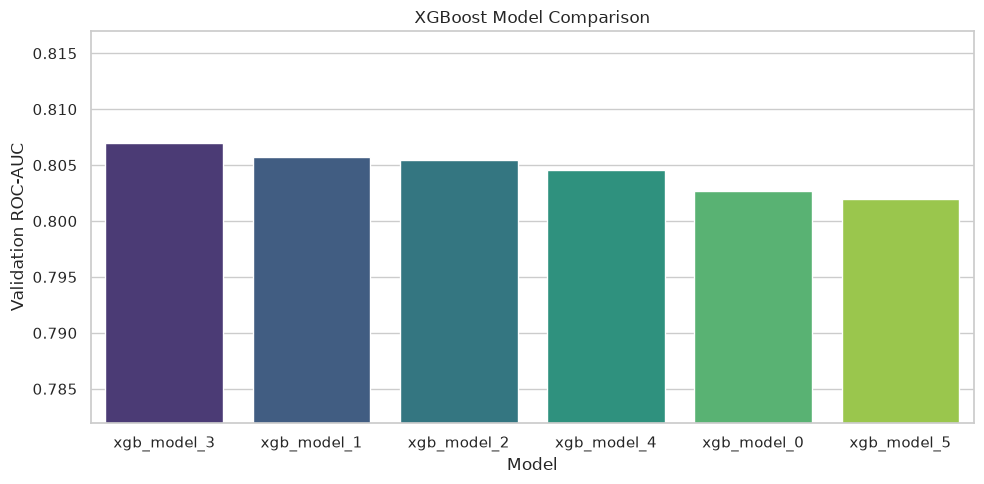

In [27]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=xgb_results,
    x="model_name",
    y="ROC-AUC",
    hue="model_name",
    legend=False,
    palette="viridis"
)

plt.title("XGBoost Model Comparison")
plt.xlabel("Model")
plt.ylabel("Validation ROC-AUC")
plt.ylim(
    max(0, xgb_results["ROC-AUC"].min() - 0.02),
    min(1, xgb_results["ROC-AUC"].max() + 0.01)
)

plt.tight_layout()
plt.show()


In [28]:

models = {
    "Decision Tree": best_dt,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

validation_predictions = {
    "Decision Tree": dt_val_predictions,
    "Random Forest": rf_val_predictions,
    "XGBoost": best_xgb.predict(dval)
}

comparison = []

for name, predictions in validation_predictions.items():

    metrics = evaluate_model(
        y_val,
        predictions
    )

    comparison.append({
        "Model": name,
        **metrics
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

best_model_name = comparison_df.iloc[0]["Model"]

print("\nBest model:", best_model_name)


,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,XGBoost,0.8070,0.4591,0.8935,0.6209,0.2306,0.3363
1,Random Forest,0.8031,0.4612,0.8952,0.6897,0.1890,0.2967
2,Decision Tree,0.7683,0.4117,0.8928,0.6361,0.1966,0.3004



Best model: XGBoost


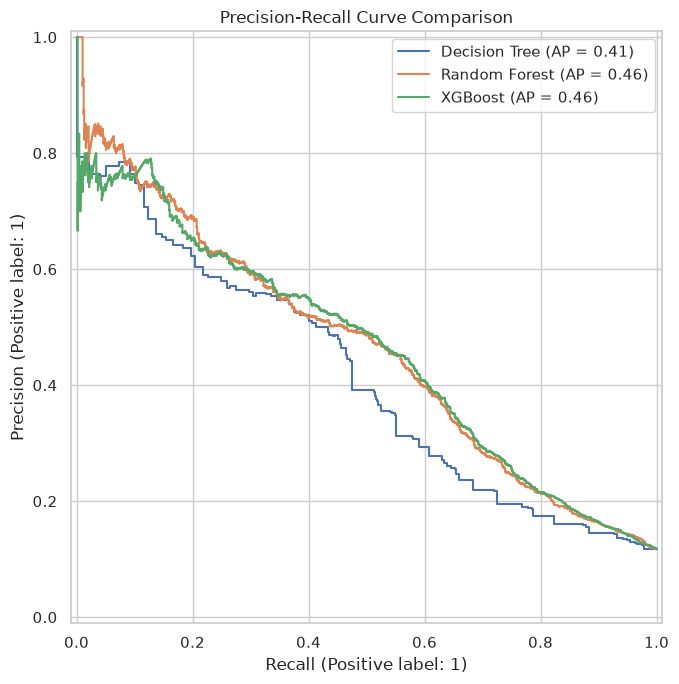

In [29]:
plt.figure(figsize=(9, 7))

for name, predictions in validation_predictions.items():

    PrecisionRecallDisplay.from_predictions(
        y_val,
        predictions,
        name=name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curve Comparison")

plt.legend()
plt.tight_layout()
plt.show()


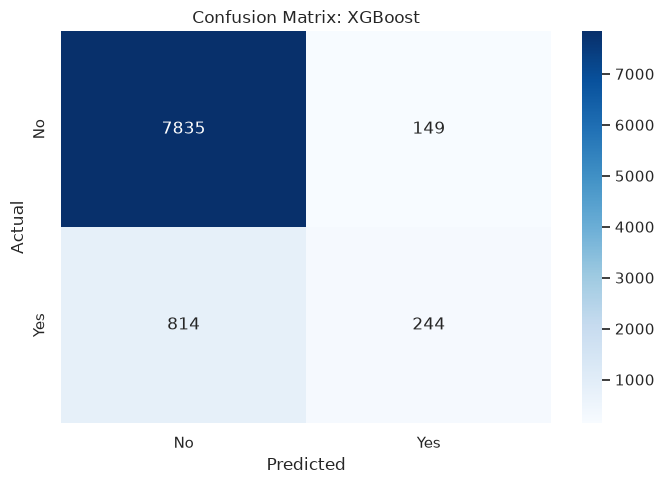

              precision    recall  f1-score   support

          No       0.91      0.98      0.94      7984
         Yes       0.62      0.23      0.34      1058

    accuracy                           0.89      9042
   macro avg       0.76      0.61      0.64      9042
weighted avg       0.87      0.89      0.87      9042



In [30]:
best_predictions = validation_predictions[best_model_name]

best_binary_predictions = (
    best_predictions >= 0.5
).astype(int)

cm = confusion_matrix(
    y_val,
    best_binary_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix: {best_model_name}")

plt.tight_layout()
plt.show()

print(
    classification_report(
        y_val,
        best_binary_predictions,
        target_names=["No", "Yes"]
    )
)